# Tutorial 8: Simulation Domains with DomainMesh

A simulation sample is more than one mesh. It has an interior where the solver
computes the fields, boundary patches where it imposes conditions, and
parameters such as the freestream velocity. `DomainMesh` keeps these parts
together, so that one call moves, transforms, checks, or saves all of them.

You will learn:

- How to build a `DomainMesh` from a CFD result
- How to inspect and iterate over its interior and boundary meshes
- How to check a domain with `validate()` and `is_boundary_watertight()`
- How to rotate a domain together with its vector fields, for data augmentation
- How to combine meshes of a domain in spatial queries, such as wall distance
- How to save and load a domain

Prerequisites: [Tutorial 2](tutorial_2_io_interop.ipynb) (`from_pyvista`),
[Tutorial 4](tutorial_4_operations.ipynb) (transformations), and
[Tutorial 7](tutorial_7_quality_repair.ipynb) (validation and watertightness).

Hardware: runs on a CPU. The first run downloads a small dataset (under 1 MB)
from the PyVista examples repository, so it needs an internet connection.

In [1]:
import tempfile

import matplotlib.pyplot as plt
import pyvista as pv
import torch

from physicsnemo.mesh import DomainMesh, Mesh
from physicsnemo.mesh.io import from_pyvista
from physicsnemo.mesh.projections import project
from physicsnemo.mesh.sampling import match_points
from physicsnemo.nn.functional.neighbors import knn

## 1. What a domain holds

The interior and the boundaries of a domain are different kinds of mesh. In a
2D flow, the interior is a triangulated region (`Mesh[2, 2]`), and each
boundary is a curve (`Mesh[1, 2]`). In 3D, the interior is a tetrahedral
volume or a point cloud, and the boundaries are surfaces. Each part carries
its own fields. `DomainMesh` is a tensorclass with three fields:

| Field | Type | Contents |
|-------|------|----------|
| `interior` | `Mesh` | The volume mesh, point cloud, or prediction surface |
| `boundaries` | `TensorDict` of `Mesh` | Named boundary patches, one per boundary condition |
| `global_data` | `TensorDict` | Domain-level quantities, such as a Reynolds number or a freestream velocity |

Its contract is that the merged boundaries enclose the interior. The
constructor does not check this; `is_boundary_watertight()` does (Section 4).

The PhysicsNeMo datapipes read samples as `DomainMesh` objects
(`physicsnemo.datapipes.readers.DomainMeshReader`), and their mesh transforms
act on whole domains.

## 2. Load a CFD result

PyVista provides a small public CFD result: 2D flow past a cylinder at a
Reynolds number of 35 ([dataset page](https://docs.pyvista.org/api/examples/_autosummary/pyvista.examples.downloads.download_cylinder_crossflow.html)).
It is a `MultiBlock` with one block per region:

| Block | Contents | Becomes |
|-------|----------|---------|
| `fluid` | Interior flow field | `interior`, a `Mesh[2, 2]` |
| `wall_cylinder` | Cylinder wall (no-slip) | `boundaries["cylinder"]`, a `Mesh[1, 2]` |
| `inlet`, `outlet`, `outlet_top`, `outlet_bottom` | Outer edges of the domain | `boundaries["freestream"]`, a `Mesh[1, 2]` |

In [2]:
case = pv.examples.download_cylinder_crossflow()
print(case)

MultiBlock (0xeff7fa493940)
  N Blocks:   6
  X Bounds:   0.000e+00, 1.500e+01
  Y Bounds:   -3.750e+00, 3.750e+00
  Z Bounds:   0.000e+00, 0.000e+00


The file stores 2D data in 3D: every point has `z = 0`, and velocities have a
zero third component. `project(keep_dims=[0, 1])` drops the z-axis. With
`transform_point_data=True` it also drops the third component of vector
fields such as `velocity`. The helper below converts one block and keeps
only the three physical fields.

In [3]:
FIELDS = ("pressure", "velocity", "vorticity_mag")


def to_2d_mesh(block, manifold_dim="auto"):
    """Convert a PyVista block to a 2D Mesh with the physical fields."""
    mesh = project(
        from_pyvista(block, manifold_dim=manifold_dim),
        keep_dims=[0, 1],
        transform_point_data=True,
    )
    return Mesh(
        points=mesh.points,
        cells=mesh.cells,
        point_data=mesh.point_data.select(*FIELDS),
    )


interior = to_2d_mesh(case["fluid"])
print(interior)

Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=14831, n_cells=29149)
    point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}


The boundary blocks hold line cells. Pass `manifold_dim=1` to keep them as
curves. The four outer patches share their corner points, so merge them into
one far-field boundary with `pv.merge`, which joins coincident points.

In [4]:
cylinder = to_2d_mesh(case["wall_cylinder"], manifold_dim=1)
farfield_block = pv.merge(
    [case[name] for name in ("inlet", "outlet", "outlet_top", "outlet_bottom")]
)
freestream = to_2d_mesh(farfield_block, manifold_dim=1)

print(f"cylinder:   {cylinder}")
print(f"freestream: {freestream}")

cylinder:   Mesh[n_manifold_dims=1, n_spatial_dims=2](n_points=63, n_cells=63)
    point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}
freestream: Mesh[n_manifold_dims=1, n_spatial_dims=2](n_points=450, n_cells=450)
    point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}


## 3. Assemble and inspect the domain

Each boundary keeps its own fields. Here both boundaries carry the same three
fields, but in general they differ: a wall might carry shear stress, and an
inlet a prescribed velocity. The freestream velocity `U_inf` applies to the
whole domain, so it goes in `global_data`. The inlet velocity is uniform, so
read it from the first inlet point.

In [5]:
U_inf = torch.from_numpy(case["inlet"].point_data["velocity"][0, :2])

dm = DomainMesh(
    interior=interior,
    boundaries={"cylinder": cylinder, "freestream": freestream},
    global_data={"U_inf": U_inf},
)
print(dm)

DomainMesh(
    interior: Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=14831, n_cells=29149)
        point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}
    boundaries:
        cylinder  : Mesh[n_manifold_dims=1, n_spatial_dims=2](n_points=63, n_cells=63)
            point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}
        freestream: Mesh[n_manifold_dims=1, n_spatial_dims=2](n_points=450, n_cells=450)
            point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}
    global_data: {U_inf: (2,)}
)


Index boundaries by name, and read `global_data` like any `TensorDict`. The
dataset stores no units, so values are in its native units.

In [6]:
print(f"boundary names: {dm.boundary_names}")
print(f"cylinder points: {dm.boundaries['cylinder'].n_points}")
print(f"U_inf = {dm.global_data['U_inf'].tolist()}")

boundary names: ['cylinder', 'freestream']
cylinder points: 63
U_inf = [35.0, 0.0]


Iterating over a domain yields `(name, mesh)` pairs: the interior first, then
the boundaries in sorted order. This is the usual way to apply a check or a
feature computation to every part.

In [7]:
for name, mesh in dm:
    print(
        f"{name:10s} manifold dims={mesh.n_manifold_dims}  points={mesh.n_points:6d}  cells={mesh.n_cells:6d}"
    )

interior   manifold dims=2  points= 14831  cells= 29149
cylinder   manifold dims=1  points=    63  cells=    63
freestream manifold dims=1  points=   450  cells=   450


## 4. Check the domain

`validate()` runs `Mesh.validate()` on every part and combines the reports.
The domain is valid only if every part is.

In [8]:
report = dm.validate()
print(f"domain valid: {report['valid']}")
print(f"  interior:   {report['interior']['valid']}")
for name, boundary_report in report["boundaries"].items():
    print(f"  {name:10s}: {boundary_report['valid']}")

domain valid: True
  interior:   True
  cylinder  : True
  freestream: True


`is_boundary_watertight()` checks the contract from Section 1. It merges all
boundaries, joins points closer than `tolerance` (default `1e-6`), and calls
`is_watertight()` on the result. In 2D, the merged boundary is watertight when
every point lies on exactly two segments: each boundary is a closed curve.

In [9]:
print(f"boundaries enclose the interior: {dm.is_boundary_watertight()}")

boundaries enclose the interior: True


## 5. Draw the domain

`DomainMesh.draw()` colors the interior by a field and draws the boundary
curves over it. It returns the matplotlib `Axes`, so you can set the axis
limits afterwards to zoom in on the cylinder.

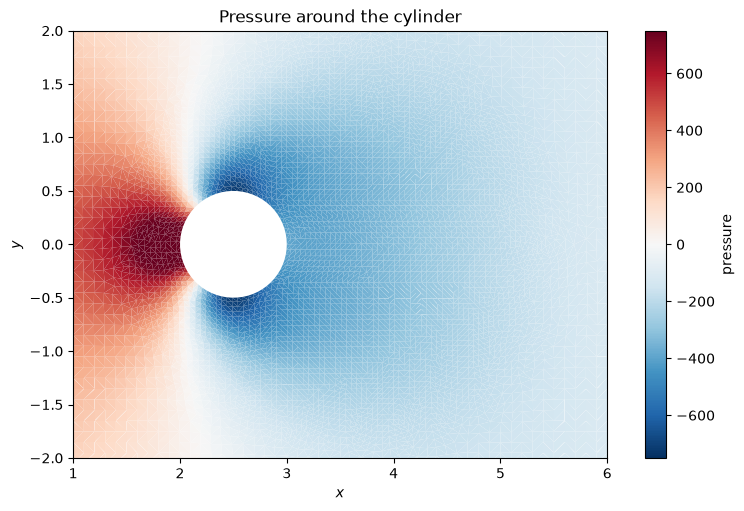

In [10]:
pressure_limit = 750.0  # symmetric color range, in native units

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
dm.draw(
    point_scalars="pressure",
    cmap="RdBu_r",
    vmin=-pressure_limit,
    vmax=pressure_limit,
    backend="matplotlib",
    ax=ax,
    show=False,
)
ax.set(
    xlim=(1, 6),
    ylim=(-2, 2),
    xlabel="$x$",
    ylabel="$y$",
    title="Pressure around the cylinder",
)
plt.show()

The flow comes from the left. Pressure is highest at the front stagnation
point of the cylinder, and lowest on its upper and lower sides.

## 6. Rotate a domain for data augmentation

A model that is not built to be rotation-equivariant can still learn to
handle different orientations if you train it on rotated copies of each
sample. A rotated copy must rotate the geometry, the boundaries, and every
vector field by the same rotation. Scalar fields, such as pressure, do not
change.

`DomainMesh.rotate()` rotates the interior and every boundary. You choose which
fields are vectors: `transform_point_data={"velocity": True}` rotates the
`velocity` field of each mesh, and `transform_global_data={"U_inf": True}`
rotates the freestream vector. Passing `True` instead of a dictionary rotates
every field whose shape fits a vector. Name the fields explicitly when a
field with that shape is not a vector, such as two unrelated channels. In
[Tutorial 9](tutorial_9_ml_integration.ipynb), `FieldSchema` makes these
declarations part of a model.

In [11]:
angle = 0.5  # radians
dm_rotated = dm.rotate(
    angle=angle,
    transform_point_data={"velocity": True},
    transform_global_data={"U_inf": True},
)

print(f"U_inf before: {dm.global_data['U_inf'].tolist()}")
print(
    f"U_inf after:  {[round(v, 3) for v in dm_rotated.global_data['U_inf'].tolist()]}"
)

U_inf before: [35.0, 0.0]
U_inf after:  [30.715, 16.78]


A rotation keeps lengths, so the speed at every point stays the same, and
pressure stays unchanged.

In [12]:
speed_before = dm.interior.point_data["velocity"].norm(dim=-1)
speed_after = dm_rotated.interior.point_data["velocity"].norm(dim=-1)
print(f"max speed change:    {(speed_after - speed_before).abs().max():.2e}")
print(
    f"max pressure change: {(dm_rotated.interior.point_data['pressure'] - dm.interior.point_data['pressure']).abs().max():.2e}"
)

max speed change:    7.63e-06
max pressure change: 0.00e+00


Draw both domains on the same pressure scale. The field turns with the
geometry.

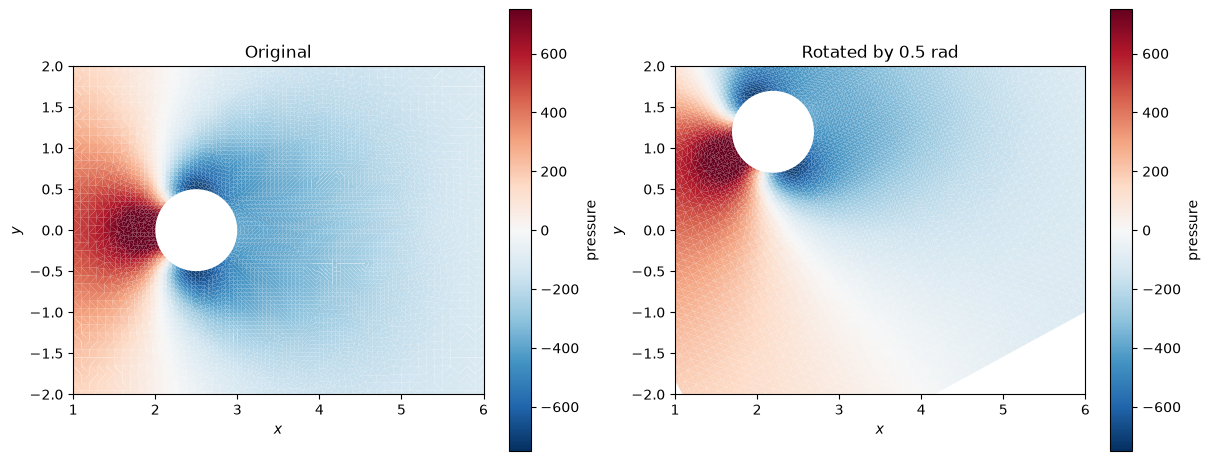

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, domain, title in zip(
    axes, (dm, dm_rotated), ("Original", f"Rotated by {angle} rad"), strict=True
):
    domain.draw(
        point_scalars="pressure",
        cmap="RdBu_r",
        vmin=-pressure_limit,
        vmax=pressure_limit,
        backend="matplotlib",
        ax=ax,
        show=False,
    )
    ax.set(xlim=(1, 6), ylim=(-2, 2), xlabel="$x$", ylabel="$y$", title=title)
plt.show()

The rotation turns about the origin, which is at the inlet, so the cylinder
also moves. Pass `center=` to rotate about another point. Transforms chain:
each call returns a new `DomainMesh`.

In [14]:
dm_transformed = dm.translate([1.0, 0.0]).rotate(angle=0.2).scale(2.0)
for name, mesh in dm_transformed:
    centroid = mesh.points.mean(dim=0)
    print(f"{name:10s} centroid = [{centroid[0]:.2f}, {centroid[1]:.2f}]")

interior   centroid = [14.92, 3.02]
cylinder   centroid = [6.86, 1.39]
freestream centroid = [16.66, 3.38]


For any other `Mesh -> Mesh` function, use `apply_to_meshes()`. The built-in
transforms use it too. Here it refines every part with one level of linear
subdivision.

In [15]:
dm_fine = dm.apply_to_meshes(lambda m: m.subdivide(levels=1))
for (name, mesh), (_, fine) in zip(dm, dm_fine, strict=True):
    print(f"{name:10s} cells: {mesh.n_cells:6d} -> {fine.n_cells:6d}")

interior   cells:  29149 -> 116596
cylinder   cells:     63 ->    126
freestream cells:    450 ->    900


The PhysicsNeMo datapipes provide random versions of these transforms for
training, such as `RandomRotateMesh` in `physicsnemo.datapipes.transforms.mesh`.

## 7. Spatial queries across meshes

Many features combine two parts of a domain. The distance from each interior
point to the nearest wall is a common input feature for flow models. A k-nearest
neighbor search (`knn`) of the interior points against the cylinder points
gives it.

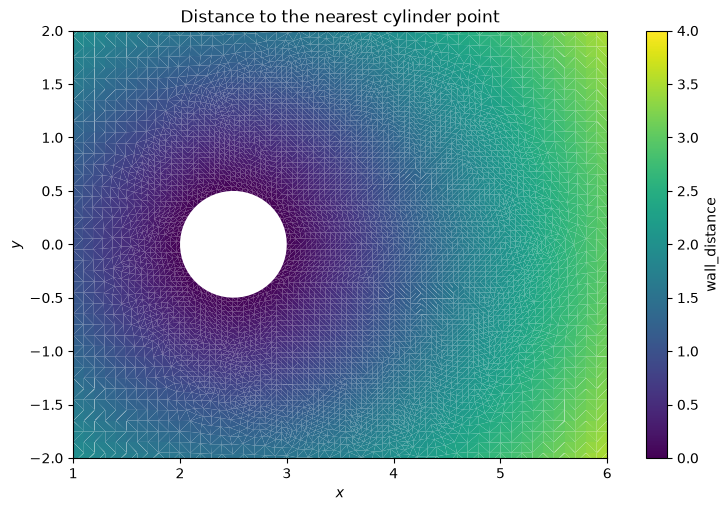

In [16]:
_, distance = knn(
    points=dm.boundaries["cylinder"].points, queries=dm.interior.points, k=1
)
dm.interior.point_data["wall_distance"] = distance[:, 0]

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
dm.draw(
    point_scalars="wall_distance",
    cmap="viridis",
    vmin=0,
    vmax=4,
    backend="matplotlib",
    ax=ax,
    show=False,
)
ax.set(
    xlim=(1, 6),
    ylim=(-2, 2),
    xlabel="$x$",
    ylabel="$y$",
    title="Distance to the nearest cylinder point",
)
plt.show()

This is the distance to the nearest cylinder vertex, not to the nearest point
on the cylinder's edges, so it is accurate to about the boundary's edge
length. For a true point-to-mesh distance, see the spatial queries in
[Tutorial 6](tutorial_6_neighbors_spatial.ipynb).

`match_points(source, target, tolerance)` finds, for each source point, the
nearest target point within `tolerance`. Here it shows that every cylinder
point is also an interior point, so you can copy wall values onto the
interior by index.

In [17]:
cylinder_index, interior_index = match_points(
    dm.boundaries["cylinder"].points, dm.interior.points, tolerance=1e-6
)
print(
    f"cylinder points matched to interior points: {len(cylinder_index)} of {dm.boundaries['cylinder'].n_points}"
)

cylinder points matched to interior points: 63 of 63


## 8. Save and load a domain

`save()` writes every tensor of the domain to a directory as memory-mapped
files. `DomainMesh.load()` reads it back. Unlike `torch.save`, this format runs
no pickled code when it loads, and it can read tensors lazily.

In [18]:
with tempfile.TemporaryDirectory() as directory:
    dm.save(directory)
    reloaded = DomainMesh.load(directory)
    print(reloaded.boundary_names)
    print(torch.equal(reloaded.interior.points, dm.interior.points))

['cylinder', 'freestream']
True


## Summary

- `DomainMesh` holds an `interior` mesh, named `boundaries`, and domain-level
  `global_data`. Boundaries can have a different manifold dimension from the
  interior.
- Iterating over a domain yields `(name, mesh)` pairs, the interior first.
- `validate()` combines the reports of every part; `is_boundary_watertight()`
  checks that the boundaries enclose the interior.
- `translate()`, `rotate()`, `scale()`, and `transform()` act on every part.
  `transform_point_data` and `transform_global_data` name the vector fields that
  rotate with the geometry.
- `apply_to_meshes(fn)` applies any `Mesh -> Mesh` function to every part; the
  built-in operations use it.
- `save()` and `DomainMesh.load()` store a domain as memory-mapped tensors.

## Next steps

- [Tutorial 9: Meshes in ML Pipelines](tutorial_9_ml_integration.ipynb) turns
  meshes into model inputs and declares a model's fields with `FieldSchema`.
- API reference:
  [core (`Mesh` and `DomainMesh`)](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/core.html),
  [sampling](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/sampling.html).
- User Guide:
  [Simulation Domains with DomainMesh](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh/domain_mesh.html).